In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("C:\Auspify Technologies ML intern\Data\Dataset.csv")
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [ ]:
print("Shape", df.shape)
print("-*" * 50)
print("Columns:", df.columns)
print("-*" * 50)
df.info()
print("-*" * 50)
print("Duplicates :", df.duplicated().sum())

Shape (8790, 10)
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Columns: Index(['show_id', 'type', 'title', 'director', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in'],
      dtype='object')
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: 

# Analyzing Target

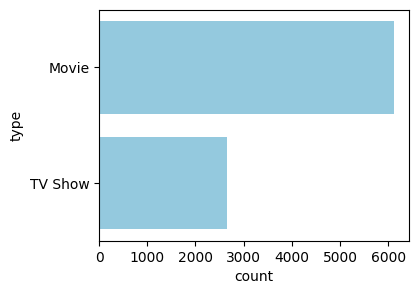

In [4]:
plt.figure(figsize=(4,3))
sns.countplot(df['type'], color='skyblue')
plt.show()

In [5]:
print(f"Unique values of country: {df['country'].unique()}")
print("-*" * 50)
print(f"Unique values of ratings: {df['rating'].unique()}")
print("-*" * 50)
print(f"Total unique values of directors: {len(df['director'].unique())}")

Unique values of country: ['United States' 'France' 'Brazil' 'United Kingdom' 'India' 'Germany'
 'Pakistan' 'Not Given' 'China' 'South Africa' 'Japan' 'Nigeria' 'Spain'
 'Philippines' 'Australia' 'Argentina' 'Canada' 'Hong Kong' 'Italy'
 'New Zealand' 'Egypt' 'Colombia' 'Mexico' 'Belgium' 'Switzerland'
 'Taiwan' 'Bulgaria' 'Poland' 'South Korea' 'Saudi Arabia' 'Thailand'
 'Indonesia' 'Kuwait' 'Malaysia' 'Vietnam' 'Lebanon' 'Romania' 'Syria'
 'United Arab Emirates' 'Sweden' 'Mauritius' 'Austria' 'Turkey'
 'Czech Republic' 'Cameroon' 'Netherlands' 'Ireland' 'Russia' 'Kenya'
 'Chile' 'Uruguay' 'Bangladesh' 'Portugal' 'Hungary' 'Norway' 'Singapore'
 'Iceland' 'Serbia' 'Namibia' 'Peru' 'Mozambique' 'Ghana' 'Zimbabwe'
 'Israel' 'Finland' 'Denmark' 'Paraguay' 'Cambodia' 'Georgia'
 'Soviet Union' 'Greece' 'West Germany' 'Iran' 'Venezuela' 'Slovenia'
 'Guatemala' 'Jamaica' 'Somalia' 'Croatia' 'Jordan' 'Luxembourg' 'Senegal'
 'Belarus' 'Puerto Rico' 'Cyprus' 'Ukraine']
-*-*-*-*-*-*-*-*-*-*-*-*-*

###  Select relevant dataset features

In [6]:
# Selecting best features
dataset = df[['type', 'release_year', 'country', 'rating', 'duration']]
dataset.head()

,type,release_year,country,rating,duration
0,Movie,2020,United States,PG-13,90 min
1,TV Show,2021,France,TV-MA,1 Season
2,TV Show,2021,United States,TV-MA,1 Season
3,Movie,2021,Brazil,TV-PG,91 min
4,Movie,1993,United States,TV-MA,125 min


In [7]:
# seperate duration into value and unit

dataset['duration_value'] = dataset['duration'].str.extract(r'(\d+)').astype(float)
dataset['duration_unit'] = dataset['duration'].str.extract(r'([A-Za-z]+)')

dataset.drop(columns=['duration'], inplace=True)
dataset['type'] = dataset['type'].map({'Movie': 0, "TV Show": 1})
dataset.head(2)

,type,release_year,country,rating,duration_value,duration_unit
0,0,2020,United States,PG-13,90.0,min
1,1,2021,France,TV-MA,1.0,Season


In [8]:
# Train Test split
from sklearn.model_selection import train_test_split

X = dataset.drop(columns=['type','duration_value','duration_unit'])
y = dataset['type']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X-train Shape:", X_train.shape)
print("X-test Shape:", X_test.shape)
print("y-train Shape:", y_train.shape)
print("y-test Shape:", y_test.shape)

X-train Shape: (7032, 3)
X-test Shape: (1758, 3)
y-train Shape: (7032,)
y-test Shape: (1758,)


###  Encode categorical variables

In [9]:
# Converting categorical data into numeric
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

num_col = ['release_year']
cat_col = ['country', 'rating']

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            num_col
        ),
        (
            'cat',
            OneHotEncoder(drop='first', handle_unknown='ignore'),
            cat_col
        )
    ]
)

X_train_tf = preprocessor.fit_transform(X_train)
X_test_tf = preprocessor.transform(X_test)

### Feature Leakage Note

We initially included `duration_value` and `duration_unit` as features. However, these features directly reveal whether a title is a Movie or TV Show. For example, `min` generally indicates a Movie, while `Season` or `Seasons` indicates a TV Show.

This caused the model to achieve an unrealistic 100% accuracy, indicating target leakage.

Therefore, we removed both duration-related features and kept only the following features for the final model:

* `rating`
* `country`
* `release_year`

This provides a more realistic and meaningful classification problem.


### Train classification models

In [10]:
# Model selection
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

models = {
    'LR': LogisticRegression(),
    "RFC": RandomForestClassifier(random_state=42)
}

for name, model in models.items():
    print(f"{'-*'*20} {name} {'-*'*20}")
    model.fit(X_train_tf, y_train)
    
    y_pred = model.predict(X_test_tf)
    print("classification report:", classification_report(y_test, y_pred))
    print('confusion matrix:', confusion_matrix(y_test, y_pred))



-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-* LR -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
classification report:               precision    recall  f1-score   support

           0       0.79      0.90      0.84      1238
           1       0.65      0.43      0.51       520

    accuracy                           0.76      1758
   macro avg       0.72      0.66      0.68      1758
weighted avg       0.75      0.76      0.75      1758

confusion matrix: [[1117  121]
 [ 298  222]]
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-* RFC -*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
classification report:               precision    recall  f1-score   support

           0       0.82      0.87      0.84      1238
           1       0.64      0.53      0.58       520

    accuracy                           0.77      1758
   macro avg       0.73      0.70      0.71      1758
weighted avg       0.76      0.77      0.77      1758

confusion matrix: [[1079  159]
 [ 242  278]]


### Model Selection

I compared Logistic Regression with Random Forest. Random Forest gave me around 77% accuracy, while Logistic Regression gave me around 76%. Since the difference was only about 1%, I decided to go with Logistic Regression because it is simpler, easier to interpret, and easier to deploy. For this project, I felt that the small accuracy improvement from Random Forest wasn't enough to justify the extra complexity.

###  Model prediction performance.

In [11]:
final_model = models['LR']
final_model.fit(X_train_tf, y_train)

# Testing the model
data = pd.DataFrame({
    "release_year": [2012],
    "country": ["Pakistan"],
    "rating": ["TV-PG"]
})

data = preprocessor.transform(data)

prediction = final_model.predict(data)[0]
probability = final_model.predict_proba(data)[0][0]

final_prediction ='Movie' if prediction==0 else 'TV Show'

print("Prediction:", final_prediction)
print('probabilities:', np.round(probability, 2)*100,'%')

Prediction: TV Show
probabilities: 22.0 %
